The definition of the PBU includes initially: AminoAcids, Fatty Acids and Conjugates (From Lipids (Kegg), LipidMaps and LOTUS), metabolites from TCA and Monosaccharides (from kegg and LOTUS). Then, the variations are computed by removing the OH group from the acid group in each of the groups presented above.

Finally, the PBU together with the Kegg database are merge to look for duplicates. Then, the duplicates are named as: [name_1, name_", ..., name_n] for n repetitions. Two molecules are considered to be the same if their InChi is the same. Even though there exists some ambiguity in the InChis definitions, this is the comparison performed by the metabolic disassembler to include a PBU in the query specific BUL. 

# Modules

In [1]:
import glob
import sys

from IPython.display import Image, display_png
from rdkit.Chem.Draw import IPythonConsole
import pickle
from rdkit import Chem
from rdkit.Chem.PandasTools import LoadSDF
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import copy
import json
import pandas as pd
import pandas.io.formats.html
import os
import metadisassembler5 as medi5
from tqdm import tqdm

# Auxiliary Functions

In [2]:
def generate_modifications(mol_input, mods):
    
    '''
    Computes all the posible modifications of a molecule containing acid groups
    '''
    
    acid = Chem.MolFromSmiles('C(=O)O')
    acid_mod = Chem.MolFromSmiles('C(=O)')
    if mol_input.HasSubstructMatch(acid):
        tpl = Chem.ReplaceSubstructs(mol_input, acid, acid_mod)
        if len(tpl) == 1:
            molecule = Chem.MolFromSmiles(Chem.MolToSmiles(tpl[0]))
            if len(molecule.GetAtoms()) > 3:
                mods.append(molecule)
            return mods
        else:
            for molecule in tpl:
                if len(molecule.GetAtoms()) > 3:
                    mods.append(Chem.MolFromSmiles(Chem.MolToSmiles(molecule)))
                mods = generate_modifications(molecule, mods)
        
    
    return mods

In [3]:
def get_leaves_json(ddd, codes):
    
    '''
    Computes the leaves of a json given in the format from Kegg Brite
    ddd: the json file in python dictionary format
    codes: an empty list
    
    returns: a list containing the names of the json leaves
    '''
    
    if len(ddd.keys()) == 2:
        for element in ddd['children']:
            get_leaves_json(element, codes)
    else:
        if ddd['name'].startswith('C'):
            codes.append(ddd['name'].split()[0])
    
    return codes

In [4]:
def find_hierarchy(ddd, query):
    matches_list = []
    for child in ddd['children']:
        matches = extract_hierarchy(child, query)
        if matches:
            matches_list.append(matches)
            
    if matches_list:
        return {'name': ddd['name'], 'children': matches_list}
    else:
        return None
    
def extract_hierarchy(elem, query):
    # Check if the children of the current element has children
    if 'children' in elem:
        matches_list = []
        # Get all the matches in the children
        for child in elem['children']:
            matches = extract_hierarchy(child, query)
            if matches:
                matches_list.append(matches)
        # If there were matches, return the current element and its children
        if matches_list:
            return {'name': elem['name'], 'children': matches_list}
        # If there were no matches, return an empty object
        else:
            return None
    # If there are no children, check if the element matches with the query
    else:
        if query in elem['name']:
            return elem
        else:
            return None
        
def post_process_hierarchy(result, hierarchies, j):
    
    if 'children' in result.keys():
        for elem in result['children']:
            hierarchies[j].append(result['name'])
            hierarchies = post_process_hierarchy(elem, hierarchies, j)
            j+=1
            hierarchies[j] = []
    else:
        hierarchies[j].append(result['name'])
        
    
    return hierarchies

def get_hierarchy(ddd, query):
    result = find_hierarchy(ddd, query)
    if result:
        hierarchies = {}
        hierarchies[0] = []
        hierarchies = post_process_hierarchy(result, hierarchies, 0)
        to_pop = []
        for key, hierarchy in hierarchies.items():
            if not hierarchy:
                to_pop.append(key)
                
        for popkey in to_pop:
            hierarchies.pop(popkey)
    
        return hierarchies
    else:
        return None
    

# Load the data

In [5]:
# Loads the json from kegg brite including the compounds with declared biological roles

with open('data/bio_roles.json', 'r') as f:
    bio_roles = json.load(f)

In [6]:
# Loads the json from kegg brite including the Lipids

with open('data/lipids.json', 'r') as f:
    lipids = json.load(f)

RDKit WARNING: [15:20:14] WARNING: not removing hydrogen atom without neighbors
[15:20:14] WARNING: not removing hydrogen atom without neighbors
RDKit WARNING: [15:20:14] WARNING: not removing hydrogen atom with dummy atom neighbors
[15:20:14] WARNING: not removing hydrogen atom with dummy atom neighbors
RDKit WARNING: [15:20:14] WARNING: not removing hydrogen atom with dummy atom neighbors
[15:20:14] WARNING: not removing hydrogen atom with dummy atom neighbors
RDKit ERROR: [15:20:15] Explicit valence for atom # 4 N, 4, is greater than permitted
[15:20:15] Explicit valence for atom # 4 N, 4, is greater than permitted
RDKit ERROR: [15:20:15] ERROR: Could not sanitize molecule ending on line 183977
[15:20:15] ERROR: Could not sanitize molecule ending on line 183977
RDKit ERROR: [15:20:15] ERROR: Explicit valence for atom # 4 N, 4, is greater than permitted
[15:20:15] ERROR: Explicit valence for atom # 4 N, 4, is greater than permitted
[15:20:21] Explicit valence for atom # 0 F, 2, is gr

RDKit ERROR: [15:20:28] ERROR: Explicit valence for atom # 10 O, 3, is greater than permitted
[15:20:28] ERROR: Explicit valence for atom # 10 O, 3, is greater than permitted
[15:20:29] Explicit valence for atom # 1 Cl, 2, is greater than permitted
RDKit ERROR: [15:20:29] Explicit valence for atom # 1 Cl, 2, is greater than permitted
RDKit ERROR: [15:20:29] ERROR: Could not sanitize molecule ending on line 2326678
[15:20:29] ERROR: Could not sanitize molecule ending on line 2326678
RDKit WARNING: [15:20:29] WARNING: not removing hydrogen atom without neighbors
RDKit WARNING: [15:20:29] WARNING: not removing hydrogen atom without neighbors
RDKit WARNING: [15:20:29] WARNING: not removing hydrogen atom without neighbors
RDKit WARNING: [15:20:29] WARNING: not removing hydrogen atom without neighbors
RDKit WARNING: [15:20:29] WARNING: not removing hydrogen atom without neighbors
RDKit WARNING: [15:20:29] WARNING: not removing hydrogen atom without neighbors
RDKit WARNING: [15:20:29] WARNING

RDKit WARNING: [15:20:36] WARNING: not removing hydrogen atom without neighbors
[15:20:36] WARNING: not removing hydrogen atom without neighbors
RDKit WARNING: [15:20:36] WARNING: not removing hydrogen atom without neighbors
RDKit WARNING: [15:20:36] WARNING: not removing hydrogen atom without neighbors
RDKit WARNING: [15:20:36] WARNING: not removing hydrogen atom without neighbors
RDKit WARNING: [15:20:36] WARNING: not removing hydrogen atom without neighbors
RDKit WARNING: [15:20:36] WARNING: not removing hydrogen atom without neighbors
RDKit WARNING: [15:20:36] WARNING: not removing hydrogen atom without neighbors
RDKit WARNING: [15:20:36] WARNING: not removing hydrogen atom without neighbors
RDKit WARNING: [15:20:36] WARNING: not removing hydrogen atom without neighbors
[15:20:36] WARNING: not removing hydrogen atom without neighbors
[15:20:36] WARNING: not removing hydrogen atom without neighbors
[15:20:36] WARNING: not removing hydrogen atom without neighbors
[15:20:36] WARNING: 

,PUBCHEM_COMPOUND_ID_TYPE,PUBCHEM_TOTAL_CHARGE,PUBCHEM_SUBSTANCE_ID,PUBCHEM_SUBSTANCE_VERSION,PUBCHEM_EXT_DATASOURCE_NAME,PUBCHEM_EXT_DATASOURCE_REGID,PUBCHEM_SUBSTANCE_COMMENT,PUBCHEM_SUBSTANCE_SYNONYM,PUBCHEM_GENERIC_REGISTRY_NAME,PUBCHEM_XREF_EXT_ID,PUBCHEM_EXT_DATASOURCE_URL,PUBCHEM_EXT_SUBSTANCE_URL,PUBCHEM_CID_ASSOCIATIONS,PUBCHEM_COORDINATE_TYPE,ID,SMILES,Molecule,PUBCHEM_BONDANNOTATIONS,PUBCHEM_NCBI_GENE_ID
0,0,0,3303,13,KEGG,C00001,"Same as: <a href=""http://pubchem.ncbi.nlm.nih....",7732-18-5\nC00001\nH2O\nWater,7732-18-5,C00001,http://www.genome.jp/kegg/,http://www.genome.jp/dbget-bin/www_bget?cpd:C0...,962 1,1\n3,3303,O,,NaN,NaN
1,0,0,3304,12,KEGG,C00002,"Same as: <a href=""http://pubchem.ncbi.nlm.nih....",56-65-5\nATP\nAdenosine 5'-triphosphate\nC00002,56-65-5,C00002,http://www.genome.jp/kegg/,http://www.genome.jp/dbget-bin/www_bget?cpd:C0...,5957 1,1\n3,3304,Nc1ncnc2c1ncn2[C@@H]1O[C@H](COP(=O)(O)OP(=O)(O...,,22 17 5\n25 29 5\n24 8 6\n26 9 6,NaN
2,0,1,3305,13,KEGG,C00003,"Same as: <a href=""http://pubchem.ncbi.nlm.nih....",53-84-9\nC00003\nDPN\nDiphosphopyridine nucleo...,53-84-9,C00003,http://www.genome.jp/kegg/,http://www.genome.jp/dbget-bin/www_bget?cpd:C0...,5893 1,1\n3,3305,NC(=O)c1ccc[n+]([C@@H]2O[C@H](COP(=O)(O)OP(=O)...,,33 10 5\n35 11 5\n24 17 5\n31 20 6\n28...,NaN
3,0,0,3306,13,KEGG,C00004,Is a reactant of enzyme EC: 1.1.1.1\nIs a reac...,58-68-4\nC00004\nDPNH\nNADH\nReduced nicotinam...,58-68-4,C00004,http://www.genome.jp/kegg/,http://www.genome.jp/dbget-bin/www_bget?cpd:C0...,439153 1,1\n3,3306,NC(=O)C1=CN([C@@H]2O[C@H](COP(=O)(O)OP(=O)(O)O...,,33 10 5\n35 11 5\n24 17 5\n31 20 6\n28...,NaN
4,0,0,3307,13,KEGG,C00005,Is a reactant of enzyme EC: 1.1.1.1\nIs a reac...,2646-71-1\nC00005\nNADPH\nReduced nicotinamide...,2646-71-1,C00005,http://www.genome.jp/kegg/,http://www.genome.jp/dbget-bin/www_bget?cpd:C0...,5884 1,1\n3,3307,NC(=O)C1=CN([C@@H]2O[C@H](COP(=O)(O)OP(=O)(O)O...,,38 14 5\n40 15 5\n28 21 5\n37 25 6\n32...,NaN

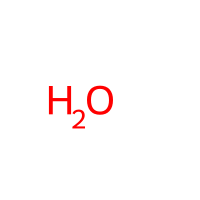
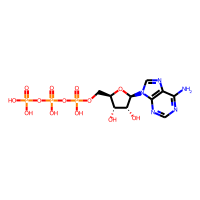
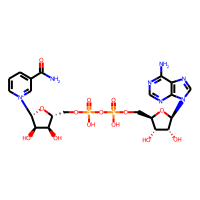
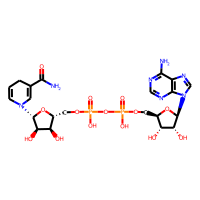
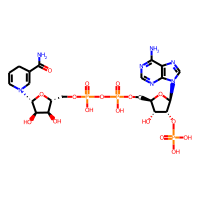

In [7]:
# Load the Kegg Database obtained through PubChem

sdf_filename = 'data/PubChem_substance_text_KEGG_records.sdf'
df = LoadSDF(sdf_filename, smilesName='SMILES', molColName='Molecule')
df.head()

,KeggID,SMILES,Molecule
0,C00001,O,"<img data-content=""rdkit/molecule"" src="""" alt=""Mol""/>"
1,C00002,Nc1ncnc2c1ncn2[C@@H]1O[C@H](COP(=O)(O)OP(=O)(O...,"<img data-content=""rdkit/molecule"" src="""" alt=""Mol""/>"
2,C00003,NC(=O)c1ccc[n+]([C@@H]2O[C@H](COP(=O)(O)OP(=O)...,"<img data-content=""rdkit/molecule"" src="""" alt=""Mol""/>"
3,C00004,NC(=O)C1=CN([C@@H]2O[C@H](COP(=O)(O)OP(=O)(O)O...,"<img data-content=""rdkit/molecule"" src="""" alt=""Mol""/>"
4,C00005,NC(=O)C1=CN([C@@H]2O[C@H](COP(=O)(O)OP(=O)(O)O...,"<img data-content=""rdkit/molecule"" src="""" alt=""Mol""/>"

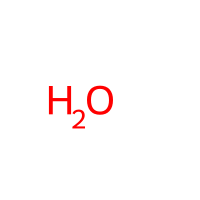
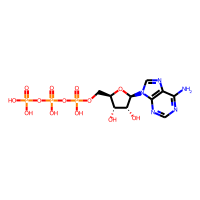
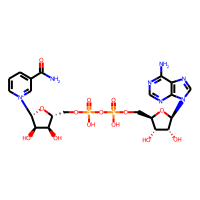
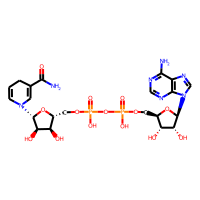
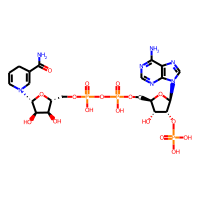

In [8]:
# Removes all columns except for the Kegg code, the SMILES and the Molecule

df = df[['PUBCHEM_EXT_DATASOURCE_REGID', 'SMILES', 'Molecule']]
df.rename({'PUBCHEM_EXT_DATASOURCE_REGID':'KeggID'}, axis=1, inplace=True)
df.head()

In [9]:
df = df.drop(df[df['KeggID'].map(lambda x: not str(x).startswith('C'))].index)
df.shape

(18733, 3)

In [10]:
len(np.unique(np.array(df['KeggID'].values)))

18733

# PBU definition

In [11]:
amino_acids = bio_roles['children'][4]['children'][1]
amino_acids

{'name': 'Amino acids',
 'children': [{'name': 'Common amino acids [Fig]',
   'children': [{'name': 'C00037  Glycine (Gly)'},
    {'name': 'C00041  Alanine (Ala)'},
    {'name': 'C00183  Valine (Val)'},
    {'name': 'C00123  Leucine (Leu)'},
    {'name': 'C00407  Isoleucine (Ile)'},
    {'name': 'C00049  Aspartic acid (Asp)'},
    {'name': 'C00152  Asparagine (Asn)'},
    {'name': 'C00025  Glutamic acid (Glu)'},
    {'name': 'C00064  Glutamine (Gln)'},
    {'name': 'C00065  Serine (Ser)'},
    {'name': 'C00188  Threonine (Thr)'},
    {'name': 'C00073  Methionine (Met)'},
    {'name': 'C00097  Cysteine (Cys)'},
    {'name': 'C00047  Lysine (Lys)'},
    {'name': 'C00062  Arginine (Arg)'},
    {'name': 'C00135  Histidine (His)'},
    {'name': 'C00148  Proline (Pro)'},
    {'name': 'C00079  Phenylalanine (Phe)'},
    {'name': 'C00082  Tyrosine (Tyr)'},
    {'name': 'C00078  Tryptophan (Trp)'}]},
  {'name': 'Other amino acids [Fig]',
   'children': [{'name': 'C05688  Selenocysteine (Sec)'},

In [12]:
fatty_acids = lipids['children'][0]['children'][0]
fatty_acids

{'name': 'FA01 Fatty Acids and Conjugates',
 'children': [{'name': 'FA0101 Straight chain fatty acids',
   'children': [{'name': 'C00058  Formic acid'},
    {'name': 'C00033  Acetic acid'},
    {'name': 'C00163  Propanoic acid'},
    {'name': 'C00246  Butanoic acid'},
    {'name': 'C00803  Pentanoic acid'},
    {'name': 'C01585  Hexanoic acid'},
    {'name': 'C17714  Heptanoic acid'},
    {'name': 'C06423  Octanoic acid'},
    {'name': 'C01601  Nonanoic acid'},
    {'name': 'C17715  Undecanoic acid'},
    {'name': 'C01571  Decanoic acid'},
    {'name': 'C02679  Dodecanoic acid'},
    {'name': 'C17076  Tridecanoic acid'},
    {'name': 'C06424  Tetradecanoic acid'},
    {'name': 'C16537  Pentadecanoic acid'},
    {'name': 'C00249  Hexadecanoic acid'},
    {'name': 'C01530  Octadecanoic acid'},
    {'name': 'C16535  Nonadecanoic acid'},
    {'name': 'C06425  Icosanoic acid'},
    {'name': 'C08281  Docosanoic acid'},
    {'name': 'C08320  Tetracosanoic acid'},
    {'name': 'C21931  Hexacos

In [13]:
monosaccharides = bio_roles['children'][2]['children'][0]
monosaccharides

{'name': 'Monosaccharides',
 'children': [{'name': 'Aldoses [Fig]',
   'children': [{'name': 'C00577  D-Glyceraldehyde'},
    {'name': 'C02426  L-Glyceraldehyde'},
    {'name': 'C01796  D-Erythrose'},
    {'name': 'C06463  D-Threose'},
    {'name': 'C00216  D-Arabinose'},
    {'name': 'C00259  L-Arabinose'},
    {'name': 'C00181  D-Xylose'},
    {'name': 'C01510  L-Xylose'},
    {'name': 'C00476  D-Lyxose'},
    {'name': 'C01508  L-Lyxose'},
    {'name': 'C00121  D-Ribose'},
    {'name': 'C00031  D-Glucose'},
    {'name': 'C00124  D-Galactose'},
    {'name': 'C01825  L-Galactose'},
    {'name': 'C00159  D-Mannose'},
    {'name': 'C01487  D-Allose'},
    {'name': 'C06464  D-Altrose'},
    {'name': 'C06465  D-Gulose'},
    {'name': 'C15923  L-Gulose'},
    {'name': 'C06466  D-Idose'},
    {'name': 'C06467  D-Talose'},
    {'name': 'C06474  3,6-Anhydrogalactose'},
    {'name': 'C06478  3,6-Anhydroglucose'}]},
  {'name': 'Ketoses [Fig]',
   'children': [{'name': 'C00184  Dihydroxyacetone'}

In [14]:
to_leaves = [monosaccharides, fatty_acids, amino_acids]

In [15]:
pbu = []
bio_roles_codes = []
for group, taxonomy in zip(to_leaves, ['MS', 'FA', 'AA']):
    codes = []
    codes = get_leaves_json(group, codes)
    for code in codes:
        pbu.append({'code':code, 'taxonomy':taxonomy, 'source':'kegg'})
pbu

[{'code': 'C00577', 'taxonomy': 'MS', 'source': 'kegg'},
 {'code': 'C02426', 'taxonomy': 'MS', 'source': 'kegg'},
 {'code': 'C01796', 'taxonomy': 'MS', 'source': 'kegg'},
 {'code': 'C06463', 'taxonomy': 'MS', 'source': 'kegg'},
 {'code': 'C00216', 'taxonomy': 'MS', 'source': 'kegg'},
 {'code': 'C00259', 'taxonomy': 'MS', 'source': 'kegg'},
 {'code': 'C00181', 'taxonomy': 'MS', 'source': 'kegg'},
 {'code': 'C01510', 'taxonomy': 'MS', 'source': 'kegg'},
 {'code': 'C00476', 'taxonomy': 'MS', 'source': 'kegg'},
 {'code': 'C01508', 'taxonomy': 'MS', 'source': 'kegg'},
 {'code': 'C00121', 'taxonomy': 'MS', 'source': 'kegg'},
 {'code': 'C00031', 'taxonomy': 'MS', 'source': 'kegg'},
 {'code': 'C00124', 'taxonomy': 'MS', 'source': 'kegg'},
 {'code': 'C01825', 'taxonomy': 'MS', 'source': 'kegg'},
 {'code': 'C00159', 'taxonomy': 'MS', 'source': 'kegg'},
 {'code': 'C01487', 'taxonomy': 'MS', 'source': 'kegg'},
 {'code': 'C06464', 'taxonomy': 'MS', 'source': 'kegg'},
 {'code': 'C06465', 'taxonomy':

In [16]:
TCA = [
    'C00158', # citrate
    'C00417', # cis-Aconitate
    'C00311', # Isocitrate
    'C00026', # 2-Oxoglutarate
    'C00091', # Succinyl-CoA
    'C00042', # Succinate
    'C00122', # Fumarate
    'C00149', # (S)-Malate
    'C00036', # Oxaloacetate
    'C00024', # Acetyl-CoA
]

In [17]:
for code in TCA:
    pbu.append({'code':code, 'taxonomy': 'TCA', 'source':'kegg'})
pbu

[{'code': 'C00577', 'taxonomy': 'MS', 'source': 'kegg'},
 {'code': 'C02426', 'taxonomy': 'MS', 'source': 'kegg'},
 {'code': 'C01796', 'taxonomy': 'MS', 'source': 'kegg'},
 {'code': 'C06463', 'taxonomy': 'MS', 'source': 'kegg'},
 {'code': 'C00216', 'taxonomy': 'MS', 'source': 'kegg'},
 {'code': 'C00259', 'taxonomy': 'MS', 'source': 'kegg'},
 {'code': 'C00181', 'taxonomy': 'MS', 'source': 'kegg'},
 {'code': 'C01510', 'taxonomy': 'MS', 'source': 'kegg'},
 {'code': 'C00476', 'taxonomy': 'MS', 'source': 'kegg'},
 {'code': 'C01508', 'taxonomy': 'MS', 'source': 'kegg'},
 {'code': 'C00121', 'taxonomy': 'MS', 'source': 'kegg'},
 {'code': 'C00031', 'taxonomy': 'MS', 'source': 'kegg'},
 {'code': 'C00124', 'taxonomy': 'MS', 'source': 'kegg'},
 {'code': 'C01825', 'taxonomy': 'MS', 'source': 'kegg'},
 {'code': 'C00159', 'taxonomy': 'MS', 'source': 'kegg'},
 {'code': 'C01487', 'taxonomy': 'MS', 'source': 'kegg'},
 {'code': 'C06464', 'taxonomy': 'MS', 'source': 'kegg'},
 {'code': 'C06465', 'taxonomy':

In [18]:
codes_pbu = [x['code'] for x in pbu]

In [19]:
bio_mol = [] #bio in mol format
bio_codes = []

for row in df.iterrows():
    if row[1]['KeggID'] in codes_pbu:
        for i, x in enumerate(pbu):
            if x['code'] == row[1]['KeggID']:
                pbu[i]['Inchi'] = Chem.MolToInchi(row[1]['Molecule'])
pbu

[{'code': 'C00577',
  'taxonomy': 'MS',
  'source': 'kegg',
  'Inchi': 'InChI=1S/C3H6O3/c4-1-3(6)2-5/h1,3,5-6H,2H2/t3-/m0/s1'},
 {'code': 'C02426',
  'taxonomy': 'MS',
  'source': 'kegg',
  'Inchi': 'InChI=1S/C3H6O3/c4-1-3(6)2-5/h1,3,5-6H,2H2/t3-/m1/s1'},
 {'code': 'C01796',
  'taxonomy': 'MS',
  'source': 'kegg',
  'Inchi': 'InChI=1S/C4H8O4/c5-2-1-8-4(7)3(2)6/h2-7H,1H2/t2-,3-,4?/m1/s1'},
 {'code': 'C06463',
  'taxonomy': 'MS',
  'source': 'kegg',
  'Inchi': 'InChI=1S/C4H8O4/c5-2-1-8-4(7)3(2)6/h2-7H,1H2/t2-,3+,4?/m1/s1'},
 {'code': 'C00216',
  'taxonomy': 'MS',
  'source': 'kegg',
  'Inchi': 'InChI=1S/C5H10O5/c6-2-1-10-5(9)4(8)3(2)7/h2-9H,1H2/t2-,3-,4+,5?/m1/s1'},
 {'code': 'C00259',
  'taxonomy': 'MS',
  'source': 'kegg',
  'Inchi': 'InChI=1S/C5H10O5/c6-2-1-10-5(9)4(8)3(2)7/h2-9H,1H2/t2-,3-,4+,5?/m0/s1'},
 {'code': 'C00181',
  'taxonomy': 'MS',
  'source': 'kegg',
  'Inchi': 'InChI=1S/C5H10O5/c6-2-1-10-5(9)4(8)3(2)7/h2-9H,1H2/t2-,3+,4-,5?/m1/s1'},
 {'code': 'C01510',
  'taxonomy': 'MS

Let us first convert the molecules to inchis so that we can easily include the entries from LOTUS and LipidMaps

In [20]:
inchis_pbu = [x['Inchi'] for x in pbu]
inchis_pbu

['InChI=1S/C3H6O3/c4-1-3(6)2-5/h1,3,5-6H,2H2/t3-/m0/s1',
 'InChI=1S/C3H6O3/c4-1-3(6)2-5/h1,3,5-6H,2H2/t3-/m1/s1',
 'InChI=1S/C4H8O4/c5-2-1-8-4(7)3(2)6/h2-7H,1H2/t2-,3-,4?/m1/s1',
 'InChI=1S/C4H8O4/c5-2-1-8-4(7)3(2)6/h2-7H,1H2/t2-,3+,4?/m1/s1',
 'InChI=1S/C5H10O5/c6-2-1-10-5(9)4(8)3(2)7/h2-9H,1H2/t2-,3-,4+,5?/m1/s1',
 'InChI=1S/C5H10O5/c6-2-1-10-5(9)4(8)3(2)7/h2-9H,1H2/t2-,3-,4+,5?/m0/s1',
 'InChI=1S/C5H10O5/c6-2-1-10-5(9)4(8)3(2)7/h2-9H,1H2/t2-,3+,4-,5?/m1/s1',
 'InChI=1S/C5H10O5/c6-1-2-3(7)4(8)5(9)10-2/h2-9H,1H2/t2-,3+,4-,5?/m0/s1',
 'InChI=1S/C5H10O5/c6-2-1-10-5(9)4(8)3(2)7/h2-9H,1H2/t2-,3+,4+,5?/m1/s1',
 'InChI=1S/C5H10O5/c6-2-1-10-5(9)4(8)3(2)7/h2-9H,1H2/t2-,3+,4+,5?/m0/s1',
 'InChI=1S/C5H10O5/c6-1-2-3(7)4(8)5(9)10-2/h2-9H,1H2/t2-,3-,4-,5?/m1/s1',
 'InChI=1S/C6H12O6/c7-1-2-3(8)4(9)5(10)6(11)12-2/h2-11H,1H2/t2-,3-,4+,5-,6?/m1/s1',
 'InChI=1S/C6H12O6/c7-1-2-3(8)4(9)5(10)6(11)12-2/h2-11H,1H2/t2-,3+,4+,5-,6?/m1/s1',
 'InChI=1S/C6H12O6/c7-1-2-3(8)4(9)5(10)6(11)12-2/h2-11H,1H2/t2-,3+,4+,

In [21]:
with open('data/LOTUS_monosaccharides.json', 'r') as f:
    LOTUS_mono = json.load(f)

In [22]:
with open('data/LipidMaps_FA.json', 'r', encoding="utf8") as f:
    LipidMaps_FA = json.load(f)

In [23]:
with open('data/LOTUS_FA.json', 'r') as f:
    LOTUS_FA = json.load(f)

In [24]:
print('Monosaccharides in LOTUS: ' + str(len(LOTUS_mono)))
print('FA in LOTUS: ' + str(len(LOTUS_FA)))
print('FA in LipidMaps: ' + str(len(LipidMaps_FA)))

Monosaccharides in LOTUS: 321
FA in LOTUS: 2489
FA in LipidMaps: 2614


In [25]:
LOTUS_mono

[{'cid': '81',
  'cmpdname': '4,5,6-Trihydroxy-2-oxo-7-phosphonooxyheptanoic acid',
  'cmpdsynonym': 'SCHEMBL2619139',
  'mw': '288.150',
  'mf': 'C7H13O10P',
  'polararea': '182.000',
  'complexity': '348.000',
  'xlogp': '-4.000',
  'heavycnt': '18',
  'hbonddonor': '6',
  'hbondacc': '10',
  'rotbonds': '8',
  'inchi': 'InChI=1S/C7H13O10P/c8-3(1-4(9)7(12)13)6(11)5(10)2-17-18(14,15)16/h3,5-6,8,10-11H,1-2H2,(H,12,13)(H2,14,15,16)',
  'isosmiles': 'C(C(C(C(COP(=O)(O)O)O)O)O)C(=O)C(=O)O',
  'inchikey': 'PJWIPEXIFFQAQZ-UHFFFAOYSA-N',
  'iupacname': '4,5,6-trihydroxy-2-oxo-7-phosphonooxyheptanoic acid',
  'annothits': ['Classification', 'Names and Identifiers', 'Patents'],
  'annothitcnt': '3',
  'cidcdate': '20050623',
  'sidsrcname': ['AAA Chemistry',
   'ABI Chem',
   'BOC Sciences',
   'ChemDB',
   'Cheminformatics Friedrich-Schiller-University Jena',
   'ChemSpider',
   'DiscoveryGate',
   'Google Patents',
   'IBM',
   'NextBio',
   'NovoSeek',
   'PATENTSCOPE (WIPO)',
   'SCRIPDB',

In [26]:
for compound in LOTUS_mono:
    if compound['inchi'] not in inchis_pbu:
        pbu.append({ 'code': compound['cid'], 'taxonomy':'MS', 'source':'LOTUS', 'Inchi':compound['inchi']})
pbu        

[{'code': 'C00577',
  'taxonomy': 'MS',
  'source': 'kegg',
  'Inchi': 'InChI=1S/C3H6O3/c4-1-3(6)2-5/h1,3,5-6H,2H2/t3-/m0/s1'},
 {'code': 'C02426',
  'taxonomy': 'MS',
  'source': 'kegg',
  'Inchi': 'InChI=1S/C3H6O3/c4-1-3(6)2-5/h1,3,5-6H,2H2/t3-/m1/s1'},
 {'code': 'C01796',
  'taxonomy': 'MS',
  'source': 'kegg',
  'Inchi': 'InChI=1S/C4H8O4/c5-2-1-8-4(7)3(2)6/h2-7H,1H2/t2-,3-,4?/m1/s1'},
 {'code': 'C06463',
  'taxonomy': 'MS',
  'source': 'kegg',
  'Inchi': 'InChI=1S/C4H8O4/c5-2-1-8-4(7)3(2)6/h2-7H,1H2/t2-,3+,4?/m1/s1'},
 {'code': 'C00216',
  'taxonomy': 'MS',
  'source': 'kegg',
  'Inchi': 'InChI=1S/C5H10O5/c6-2-1-10-5(9)4(8)3(2)7/h2-9H,1H2/t2-,3-,4+,5?/m1/s1'},
 {'code': 'C00259',
  'taxonomy': 'MS',
  'source': 'kegg',
  'Inchi': 'InChI=1S/C5H10O5/c6-2-1-10-5(9)4(8)3(2)7/h2-9H,1H2/t2-,3-,4+,5?/m0/s1'},
 {'code': 'C00181',
  'taxonomy': 'MS',
  'source': 'kegg',
  'Inchi': 'InChI=1S/C5H10O5/c6-2-1-10-5(9)4(8)3(2)7/h2-9H,1H2/t2-,3+,4-,5?/m1/s1'},
 {'code': 'C01510',
  'taxonomy': 'MS

In [27]:
for compound in LOTUS_FA:
    if compound['inchi'] not in inchis_pbu:
        pbu.append({ 'code': compound['cid'], 'taxonomy':'FA', 'source':'LOTUS', 'Inchi':compound['inchi']})
        

In [28]:
for compound in LipidMaps_FA:
    if compound['inchi'] not in inchis_pbu:
        pbu.append({ 'code': compound['cid'], 'taxonomy':'FA', 'source':'LipidMaps', 'Inchi':compound['inchi']})
        

In [29]:
print('Number of PBUs before modifications: ' + str(len(pbu)))

Number of PBUs before modifications: 5468


In [30]:
with open('data/PBU_v2_Mar23.pkl', 'wb') as f:
    pickle.dump(pbu, f)

Now, the pbu coming from the network analysis are included in the pbu.

In [31]:
with open('v2/new_pbu_kegg.pkl', 'rb') as f:
    new_pbus = pickle.load(f)

FileNotFoundError: [Errno 2] No such file or directory: 'v2/new_pbu_kegg.pkl'

In [32]:
with open('BRITE.json', 'r') as f:
    BRITE = json.load(f)

In [33]:
with open('kegg_matrix/translator.json', 'r') as f:
    translator = json.load(f)

FileNotFoundError: [Errno 2] No such file or directory: 'kegg_matrix/translator.json'

In [99]:
depth = 3
brite = {}
taxonomy = []
brite_flag=False

new_pbu_complete = []
pbu_item = {}
for kegg in new_pbus:
    
    codes = translator[kegg]
    mol = df.loc[df['KeggID']==codes[0]]['Molecule'].values[0]
    inchi = Chem.MolToInchi(mol)
    
    if inchi in inchis_pbu:
        continue
        
    pbu_item['code'] = codes[0]
    pbu_item['source'] = 'kegg'
    pbu_item['Inchi'] = inchi
    
    hierarchies = get_hierarchy(BRITE, codes[0])
    if hierarchies:
        for key, hierarchy in hierarchies.items():
            taxonomy = hierarchy[depth]
            if taxonomy == 'Amino acids':
                brite_flag = True
                tax = 'AA'
                break
            if taxonomy == 'Monosaccharides':
                brite_flag = True
                tax = 'MS'
                break
            if taxonomy == 'Fatty acids [Fig]' or taxonomy[-1] == 'Fatty acids' or taxonomy[-1] == 'FA01 Fatty Acids and Conjugates':
                brite_flag=True
                tax = 'FA'
                break
            else:
                brite_flag = True
                tax = taxonomy
                break
                
        if brite_flag:
            pbu_item['taxonomy'] = tax
            brite_flag = False
    else:
        pbu_item['taxonomy'] = 'Not in BRITE'
    
    new_pbu_complete.append(pbu_item)
    pbu_item = {}
    
#labels, count = np.unique([x['taxonomy'] for x in new_pbu_complete], return_counts = True)
#print(dict(zip(labels, count)))
new_pbu_complete

[{'code': 'C00256',
  'source': 'kegg',
  'Inchi': 'InChI=1S/C3H6O3/c1-2(4)3(5)6/h2,4H,1H3,(H,5,6)/t2-/m1/s1',
  'taxonomy': 'Not in BRITE'},
 {'code': 'C05198',
  'source': 'kegg',
  'Inchi': 'InChI=1S/C10H13N5O3/c1-4-6(16)7(17)10(18-4)15-3-14-5-8(11)12-2-13-9(5)15/h2-4,6-7,10,16-17H,1H3,(H2,11,12,13)/t4-,6-,7-,10-/m1/s1',
  'taxonomy': 'Not in BRITE'},
 {'code': 'C00559',
  'source': 'kegg',
  'Inchi': 'InChI=1S/C10H13N5O3/c11-9-8-10(13-3-12-9)15(4-14-8)7-1-5(17)6(2-16)18-7/h3-7,16-17H,1-2H2,(H2,11,12,13)/t5-,6+,7+/m0/s1',
  'taxonomy': 'Nucleosides [Fig]'},
 {'code': 'C00212',
  'source': 'kegg',
  'Inchi': 'InChI=1S/C10H13N5O4/c11-8-5-9(13-2-12-8)15(3-14-5)10-7(18)6(17)4(1-16)19-10/h2-4,6-7,10,16-18H,1H2,(H2,11,12,13)/t4-,6-,7-,10-/m1/s1',
  'taxonomy': 'Nucleosides [Fig]'},
 {'code': 'C00020',
  'source': 'kegg',
  'Inchi': 'InChI=1S/C10H14N5O7P/c11-8-5-9(13-2-12-8)15(3-14-5)10-7(17)6(16)4(22-10)1-21-23(18,19)20/h2-4,6-7,10,16-17H,1H2,(H2,11,12,13)(H2,18,19,20)/t4-,6-,7-,10-/m1/s1

In [101]:
complete_pbu = pbu + new_pbu_complete

In [103]:
with open('v2/to_map4_pbu.pkl', 'wb') as f:
    pickle.dump(complete_pbu, f)

# Modifications generation
The pbu has been cleaned by using the map4 fingerprint, eliminating those structures that may interfere with the amino acids structures. The analysis performe in notebook PBU_analysis_v2 has been also taken into account.

In [61]:
with open('v2/pbu_clean.pkl', 'rb') as f:
    pbu_clean = pickle.load(f)

In [62]:
assert 'C00408' in [x['code'] for x in pbu_clean]

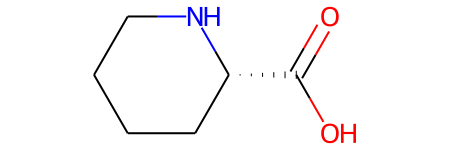

In [63]:
for x in pbu_clean:
    if x['code'] == 'C00408':
        save = x['Inchi']
Chem.MolFromInchi(save)

In [64]:
bio_codes = [x['code'] for x in pbu_clean]
bio_mol = []
for k, code in enumerate(bio_codes):
    if code in df['KeggID'].values:
        bio_mol.append(df[df['KeggID'] == code]['Molecule'].values[0])
    else:
        bio_mol.append(Chem.MolFromInchi(pbu_clean[k]['Inchi']))


In [65]:
len(bio_mol)

2435

In [66]:
len(bio_codes)

2435

In [67]:
bio_mol_mods = []
bio_codes_mods = []
i=1
for molecule, code in zip(bio_mol, bio_codes):
    if i == 766: # This molecule leads to an explosion in the number of modifications
        i+=1
        continue
    print(f'Computing: [{i}/{len(bio_mol)}]', end='\r')
    mods = []
    mods = generate_modifications(molecule, mods)
    for j, mod in enumerate(mods):
        bio_mol_mods.append(mod)
        bio_codes_mods.append(code + '_mod_' + str(j))
    i+=1
len(bio_mol_mods)

5446

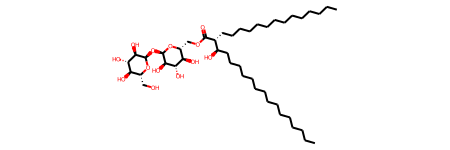

In [68]:
bio_mol[880]

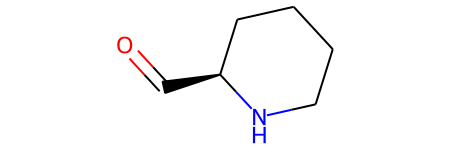

In [69]:
ddd = dict(zip(bio_codes_mods, bio_mol_mods))
ddd['C00408_mod_0']

In [70]:
# Creates the FINAL pbu (with the names removing duplicates)
# The displayed named in the results.txt is the corresponding to the BUL matching the PBU inchi. 
# Therefore, no necessity of including the ambiguity of names [name1, name2] in the pbu

pbu = {} # code:molecule
invalid_inchi = []

for mol, code in zip(bio_mol, bio_codes):
    inchi = Chem.MolToInchi(mol)
    formula = inchi.split('/')[1]
    if '.' in formula:
        print('Invalid Mol')
        invalid_inchi.append(inchi)
        continue
    if inchi != '': # Remove those generated modifications without structural sense
        pbu[code] = mol
    else:
        print('Invalid mol')

for mol, code in zip(bio_mol_mods, bio_codes_mods):
    inchi = Chem.MolToInchi(mol)
    formula = inchi.split('/')[1]
    if '.' in formula:
        print('Invalid Mol')
        invalid_inchi.append(inchi)
        continue
    if inchi != '':
        pbu[code] = mol
    else:
        print('Invalid mod')

Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Inva

Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Inva

Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Invalid Mol
Inva

In [71]:
len(pbu)

5006

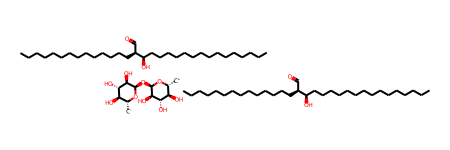

In [72]:
Chem.MolFromInchi(invalid_inchi[35])

In [73]:
with open('v2/pbu_codes.pkl', 'wb') as f:
    pickle.dump(list(pbu.keys()), f)

In [74]:
pbu

{'C00577': <rdkit.Chem.rdchem.Mol at 0x2a6d140e5d0>,
 'C02426': <rdkit.Chem.rdchem.Mol at 0x2a6d36f5120>,
 'C01796': <rdkit.Chem.rdchem.Mol at 0x2a6d261c0d0>,
 'C06463': <rdkit.Chem.rdchem.Mol at 0x2a6d7c8aa30>,
 'C00216': <rdkit.Chem.rdchem.Mol at 0x2a6d13464e0>,
 'C00259': <rdkit.Chem.rdchem.Mol at 0x2a6d135f850>,
 'C00181': <rdkit.Chem.rdchem.Mol at 0x2a6d1332350>,
 'C01510': <rdkit.Chem.rdchem.Mol at 0x2a6d259df30>,
 'C00476': <rdkit.Chem.rdchem.Mol at 0x2a6d13d2940>,
 'C01508': <rdkit.Chem.rdchem.Mol at 0x2a6d259d2b0>,
 'C00121': <rdkit.Chem.rdchem.Mol at 0x2a6d130d350>,
 'C00031': <rdkit.Chem.rdchem.Mol at 0x2a6d12dc350>,
 'C00124': <rdkit.Chem.rdchem.Mol at 0x2a6d1310170>,
 'C01825': <rdkit.Chem.rdchem.Mol at 0x2a6d26275d0>,
 'C00159': <rdkit.Chem.rdchem.Mol at 0x2a6d1324f30>,
 'C01487': <rdkit.Chem.rdchem.Mol at 0x2a6d2592940>,
 'C06464': <rdkit.Chem.rdchem.Mol at 0x2a6d7c8b080>,
 'C06465': <rdkit.Chem.rdchem.Mol at 0x2a6d7c8b5d0>,
 'C15923': <rdkit.Chem.rdchem.Mol at 0x2a6eb49

In [75]:
'C00408' in pbu.keys() 

True

# Merge PBU and BUL
Bul (kegg) and pbu are going to be merged as well as duplicates will be removed.

In [76]:
df.shape

(16612, 3)

In [77]:
def remove_duplicates_kegg(df, pbu):
    '''
    def was_visited(visited_molecules, mol):
        
        # Decides whelther a molecules is is a list of molecules and where
        
        for where, visited_mol in enumerate(visited_molecules):
            if len(mol.GetSubstructMatch(visited_mol)) == mol.GetNumAtoms(): # Are the same molecule
                return where, True
            
        return None, False
    '''          
                
            
    
    names = [] # a list of lists of identifiers
    molecules = [] # a list containing the molecules
    
    # Merge the original df with the pbu
    i=1
    df_pbu = pd.DataFrame()
    for code, mol in pbu.items():
        print(f'Computing[1/2]: [{i}/{len(pbu)}]', end='\r')
        df_aux = pd.DataFrame([[code, Chem.MolToSmiles(mol), mol]], columns=['KeggID', 'SMILES', 'Molecule'])
        df_pbu = pd.concat([df_pbu, df_aux])
        i+=1
        
    df = pd.concat([df, df_pbu])
    
    visited_inchis = []
    i =1
    for row in df.iterrows():
        print(f'Computing [2/2]: [{i}/{df.shape[0]}]', end='\r')
        inchi = Chem.MolToInchi(row[1]['Molecule'])+
        if inchi not in visited_inchis:
            visited_inchis.append(inchi)
            molecules.append(row[1]['Molecule'])
            names.append([row[1]['KeggID']])
        else:
            where = visited_inchis.index(inchi)
            if row[1]['KeggID'] not in names[where]:
                names[where].append(row[1]['KeggID'])
        i+=1
    
    
    '''       
    visited_molecules = []
    i =0 
    for row in df.iterrows():
        print('Computing: ' + str(i/df.shape[0]), end='\r')
        mol = row[1]['Molecule']
        if mol.GetNumAtoms() == 0:
            continue
        where, visited_mol = was_visited(visited_molecules, mol)
        if not visited_mol:
            visited_molecules.append(mol)
            molecules.append(mol)
            names.append([row[1]['KeggID']])
        else:
            names[where].append(row[1]['KeggID'])
        i+=1
    '''
    return names, molecules

In [78]:
df_empty = pd.DataFrame()

,KeggID,SMILES,Molecule
0,C00024,O=C[C@]1(O)C[C@@H](O)[C@@H](O)[C@H](O)C1,

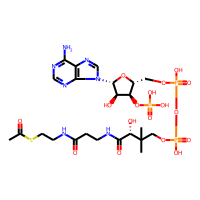

In [79]:
df_aux = pd.DataFrame([['C00024', Chem.MolToSmiles(mol), pbu['C00024']]], columns=['KeggID', 'SMILES', 'Molecule'])
df_aux

In [80]:
codes_no_inchi = df[df['Molecule'].map(lambda x: Chem.MolToInchi(x)=='')]['KeggID'].values
codes_no_inchi

array([], dtype=object)

In [81]:
len(codes_no_inchi)

0

In [82]:
with open('v2/codes_no_inchi.pkl', 'wb') as f:
    pickle.dump(codes_no_inchi, f)

In [83]:
# Remove the molecules 'without' inchi and saves the codes

df = df.drop(df[df['Molecule'].map(lambda x: Chem.MolToInchi(x)=='')].index)
df.shape

(16612, 3)

In [84]:
names, molecules = remove_duplicates_kegg(df, pbu)

In [85]:
len(names)

20035

In [86]:
lst = [x for x in names if len(x) > 1]
print('More than 1 name: ' + str(len(lst)/len(names)*100) + ' %')

More than 1 name: 2.5954579485899676 %


In [87]:
with open('v2/names_kegg.pkl', 'wb') as f:
    pickle.dump(names, f)

In [88]:
with open('v2/molecules_kegg.pkl', 'wb') as f:
    pickle.dump(molecules, f)

In [89]:
with open('v2/molecules_kegg.pkl', 'rb') as f:
    molecules = pickle.load(f)

In [90]:
import rdkit as rd
rd.__version__

'2021.09.3'

In [91]:
BUL = medi5.Library.Library()
i = 1
for name, mol in zip(names, molecules):
    print(f'Building BUL: [{i}/{len(molecules)}]', end ='\r')
    cpd = medi5.Compound.Compound()
    cpd._input_rdkmol(mol)
    BUL._append_cpd(cpd, name)
    i+=1

In [92]:
# Ensures that the names are not repeated...

for i, name in enumerate(BUL.names):
    BUL.names[i] = list(set(name))

In [93]:
pbu = {code: Chem.MolToInchi(x) for code, x in pbu.items()}

In [94]:
pbu

{'C00577': 'InChI=1S/C3H6O3/c4-1-3(6)2-5/h1,3,5-6H,2H2/t3-/m0/s1',
 'C02426': 'InChI=1S/C3H6O3/c4-1-3(6)2-5/h1,3,5-6H,2H2/t3-/m1/s1',
 'C01796': 'InChI=1S/C4H8O4/c5-2-1-8-4(7)3(2)6/h2-7H,1H2/t2-,3-,4?/m1/s1',
 'C06463': 'InChI=1S/C4H8O4/c5-2-1-8-4(7)3(2)6/h2-7H,1H2/t2-,3+,4?/m1/s1',
 'C00216': 'InChI=1S/C5H10O5/c6-2-1-10-5(9)4(8)3(2)7/h2-9H,1H2/t2-,3-,4+,5?/m1/s1',
 'C00259': 'InChI=1S/C5H10O5/c6-2-1-10-5(9)4(8)3(2)7/h2-9H,1H2/t2-,3-,4+,5?/m0/s1',
 'C00181': 'InChI=1S/C5H10O5/c6-2-1-10-5(9)4(8)3(2)7/h2-9H,1H2/t2-,3+,4-,5?/m1/s1',
 'C01510': 'InChI=1S/C5H10O5/c6-1-2-3(7)4(8)5(9)10-2/h2-9H,1H2/t2-,3+,4-,5?/m0/s1',
 'C00476': 'InChI=1S/C5H10O5/c6-2-1-10-5(9)4(8)3(2)7/h2-9H,1H2/t2-,3+,4+,5?/m1/s1',
 'C01508': 'InChI=1S/C5H10O5/c6-2-1-10-5(9)4(8)3(2)7/h2-9H,1H2/t2-,3+,4+,5?/m0/s1',
 'C00121': 'InChI=1S/C5H10O5/c6-1-2-3(7)4(8)5(9)10-2/h2-9H,1H2/t2-,3-,4-,5?/m1/s1',
 'C00031': 'InChI=1S/C6H12O6/c7-1-2-3(8)4(9)5(10)6(11)12-2/h2-11H,1H2/t2-,3-,4+,5-,6?/m1/s1',
 'C00124': 'InChI=1S/C6H12O6/c7-1-

In [95]:
with open('metadisassembler5/data/PBU_v2.pkl', 'wb') as f:
    pickle.dump(pbu, f)

In [96]:
with open('metadisassembler5/data/BUL_v2.pkl', 'wb') as f:
    pickle.dump(BUL, f)

In [97]:
for k, name in enumerate(BUL.names):
    if 'C00148_mod_0' in name:
        print(k)

18338
